# Lecture 17 Notebook - Machine Learning with Iris Dataset

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [7]:
iris = sns.load_dataset('iris')
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


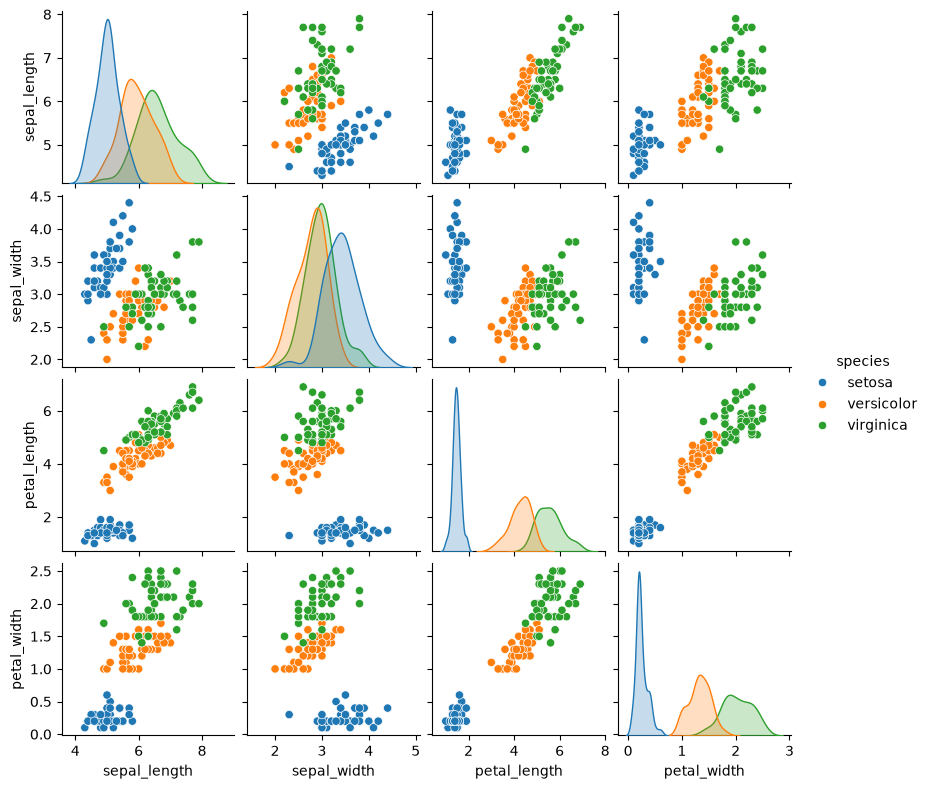

In [8]:
sns.pairplot(iris, hue='species', height=2)

<Axes: xlabel='petal_width', ylabel='petal_length'>

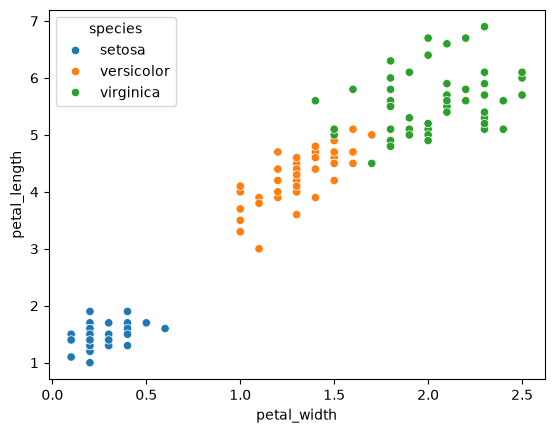

In [9]:
sns.scatterplot(data = iris, x = 'petal_width', y = 'petal_length', hue='species')

Determining which 2 flower features are best to classify flowers of the 3 species.

In [19]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Load iris data
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["species"] = iris.target_names[iris.target]

# Use just the two petal features
X = df[["petal length (cm)", "petal width (cm)"]]
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

model = LogisticRegression(max_iter=5000)
model.fit(X_train, y_train)
preds = model.predict(X_test)

accuracy = accuracy_score(y_test, preds)
print("Accuracy using petal length + petal width:", accuracy)

Accuracy using petal length + petal width: 0.9333333333333333


In [20]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["species"] = iris.target_names[iris.target]

pairs = [
    ("sepal length (cm)", "sepal width (cm)"),
    ("sepal length (cm)", "petal length (cm)"),
    ("sepal length (cm)", "petal width (cm)"),
    ("sepal width (cm)", "petal length (cm)"),
    ("sepal width (cm)", "petal width (cm)"),
    ("petal length (cm)", "petal width (cm)")
]

for a, b in pairs:
    X = df[[a, b]]
    y = df["species"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=42, stratify=y
    )

    model = LogisticRegression(max_iter=5000)
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    acc = accuracy_score(y_test, preds)

    print(f"{a:>18} + {b:>18} -> {acc:.3f}")

 sepal length (cm) +   sepal width (cm) -> 0.733
 sepal length (cm) +  petal length (cm) -> 0.933
 sepal length (cm) +   petal width (cm) -> 0.889
  sepal width (cm) +  petal length (cm) -> 0.933
  sepal width (cm) +   petal width (cm) -> 0.867
 petal length (cm) +   petal width (cm) -> 0.933


The best pair is:

petal length
petal width

because those two features give the clearest separation of the three iris species.

Searched codebase for "why not use linearRegression instead of logistic", 27 results

## Why not use linear regression?

Because this is a classification problem, not a regression problem.

### The key difference
- Linear regression predicts a continuous number.
- Logistic regression predicts a class label or class probability.
- Your iris task is to classify flowers into 3 species:
  - setosa
  - versicolor
  - virginica

So the model should be built for classification, not for predicting a numeric value.

---

## Why logistic regression is the better fit here
Logistic regression is designed to model:
- the probability of belonging to each class
- and then choose the most likely class

For iris, the target is categorical, so logistic regression is a natural choice.

If you used linear regression instead, the model would try to predict a numeric output, which is not appropriate for class labels like:
```python
"setosa", "versicolor", "virginica"
```

You would first have to convert species to numbers, and even then the results are not as natural or interpretable for classification.

---

## In short
Use:
- Logistic regression for classification
- Linear regression for predicting continuous values

Example:
```python
# classification
model = LogisticRegression()

# not for this problem
# model = LinearRegression()
```

---

## For your iris project
This is exactly why the notebook uses:
```python
from sklearn.linear_model import LogisticRegression
```

It is a classifier for the species labels, and it matches the task much better than linear regression.

If you want, I can also show you what would go wrong if you tried to use linear regression on the iris dataset.

### 1) Choose a class of model and import appropriate package

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB 

### 2) Choose model parameters and instantiate class

In [11]:
model = GaussianNB()   

### 3) Arrange data into a features matrix and target vector, split data into training and testing sets

In [12]:
X_iris = iris.drop('species', axis=1)
X_iris.shape

(150, 4)

In [13]:
y_iris = iris['species']
y_iris.shape

(150,)

In [14]:
Xtrain, Xtest, ytrain, ytest = train_test_split(X_iris, y_iris,
                                                random_state=1)

### 4) Fit the model to your data

In [15]:
model.fit(Xtrain, ytrain)                 

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](3,)","[37.,34.,41.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](3,)","[0.33,0.3 ,0.37]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[<U10](3,)","['setosa','versicolor','virginica']"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,3.141e-09
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['sepal_length','sepal_width','petal_length','petal_width']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](3, 4)","[[4.95,3.36,1.47,0.24], [5.96,2.74,4.24,1.31], [6.52,2.96,5.53,2. ]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](3, 4)","[[0.11,0.13,0.03,0.01], [0.29,0.11,0.22,0.04], [0.37,0.1 ,0.31,0.08]]"


### 5) Apply the model

In [16]:
y_model = model.predict(Xtest) 

### 6) Evaluate the model

In [17]:
from sklearn.metrics import accuracy_score
accuracy_score(ytest, y_model)

0.9736842105263158